# Домашнє завдання до модуля «Алгоритми навчання з вчителем Ч.3»

Мета: побудувати kNN-регресор для прогнозування рівня заробітної плати нових працівників компанії та оцінити його точність на валідаційному наборі.

### 1. Імпорт необхідних пакетів

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer, OneHotEncoder
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import (mean_absolute_error,
                             mean_absolute_percentage_error,
                             r2_score)

Набори даних беремо з локальної папки репозиторію курсу, а якщо її немає (наприклад, під час запуску в Google Colab) — безпосередньо з GitHub.

In [2]:
DATA_DIR = Path('../datasets')

DATA_URL = ('https://raw.githubusercontent.com/goitacademy/'
            'MACHINE-LEARNING-NEO/main/')


def data_path(filename, folder='datasets'):
    local = DATA_DIR / filename
    return local if local.exists() else DATA_URL + folder + '/' + filename

### 2. Завантаження наборів даних

In [3]:
data = pd.read_csv(data_path('mod_04_hw_train_data.csv'))
valid = pd.read_csv(data_path('mod_04_hw_valid_data.csv'))

print(f'train: {data.shape} | valid: {valid.shape}')

train: (249, 9) | valid: (7, 9)


In [4]:
data.head()

,Name,Phone_Number,Experience,Qualification,University,Role,Cert,Date_Of_Birth,Salary
0,Jennifer Hernandez,120-602-1220,3.0,Msc,Tier2,Mid,Yes,25/08/1972,98000
1,Timothy Walker,840-675-8650,5.0,PhD,Tier2,Senior,Yes,03/12/2013,135500
2,David Duran,556-293-8643,5.0,Msc,Tier2,Senior,Yes,19/07/2002,123500
3,Gloria Ortega,463-559-7474,3.0,Bsc,Tier3,Mid,No,19/02/1970,85000
4,Matthew Steele,968-091-7683,5.0,Bsc,Tier2,Senior,Yes,20/02/1970,111500


### 3. Первинний дослідницький аналіз даних

Перевіряємо типи ознак і наявність пропущених значень.

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Name           249 non-null    object 
 1   Phone_Number   249 non-null    object 
 2   Experience     247 non-null    float64
 3   Qualification  248 non-null    object 
 4   University     249 non-null    object 
 5   Role           246 non-null    object 
 6   Cert           247 non-null    object 
 7   Date_Of_Birth  249 non-null    object 
 8   Salary         249 non-null    int64  
dtypes: float64(1), int64(1), object(7)
memory usage: 17.6+ KB


In [6]:
data.isna().sum()

Name             0
Phone_Number     0
Experience       2
Qualification    1
University       0
Role             3
Cert             2
Date_Of_Birth    0
Salary           0
dtype: int64

Пропуски є в чотирьох колонках, але їх дуже мало (від 1 до 3 значень), тому відновимо їх стандартними засобами `SimpleImputer`.

Далі дивимось на кількість унікальних значень, щоб зрозуміти, які ознаки взагалі придатні для моделювання.

In [7]:
data.nunique()

Name             248
Phone_Number     249
Experience         5
Qualification      3
University         3
Role               3
Cert               2
Date_Of_Birth    247
Salary            84
dtype: int64

Ознаки `Name` і `Phone_Number` є фактично ідентифікаторами: кількість унікальних значень майже дорівнює кількості спостережень. Вони не несуть жодної інформації про рівень оплати праці й не будуть доступні для нових працівників у придатному для моделі вигляді, тому їх використовувати недоцільно.

Окремо перевіримо ознаку `Date_Of_Birth` — розрахуємо на її основі вік працівника й подивимось, чи пов'язаний він із зарплатою.

In [8]:
tmp = data.copy()

tmp['Age'] = (2024 -
              pd.to_datetime(tmp['Date_Of_Birth'], dayfirst=True).dt.year)

tmp[['Age', 'Experience', 'Salary']].corr()['Salary']

Age           0.070804
Experience    0.814427
Salary        1.000000
Name: Salary, dtype: float64

Вік практично не корелює із зарплатою (0.07), тоді як стаж роботи має сильний зв'язок (0.81). До того ж значення дат народження виглядають нереалістично (є працівники з роком народження 2013 і стажем 5 років), тобто ця колонка містить некоректні дані. Отже, `Date_Of_Birth` також відкидаємо.

Розглянемо решту ознак у розрізі рівня оплати.

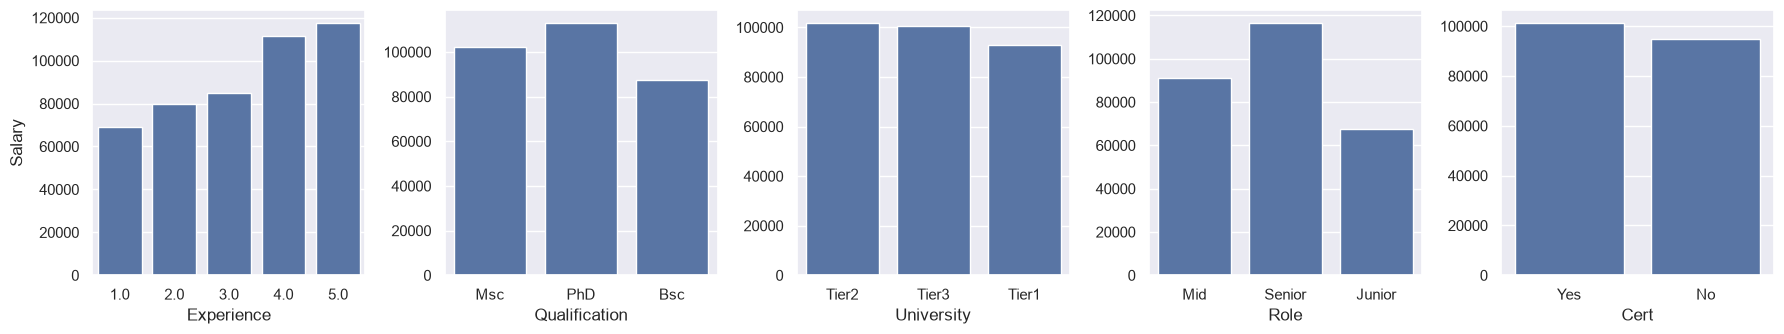

In [9]:
sns.set_theme()

features = ['Experience', 'Qualification', 'University', 'Role', 'Cert']

fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))

for ax, col in zip(axes, features):
    sns.barplot(data=data, x=col, y='Salary', ax=ax, errorbar=None)
    ax.set(xlabel=col, ylabel='Salary' if col == 'Experience' else '')

plt.tight_layout()
plt.show()

Усі п'ять ознак впливають на зарплату: вона зростає зі стажем, рівнем освіти, посадою та наявністю сертифіката. Тому залишаємо їх усі для навчання моделі.

In [10]:
X_train = data[features].copy()
y_train = data['Salary']

X_valid = valid[features].copy()
y_valid = valid['Salary']

### 4. Обробка ознак

Відновлюємо пропуски: числові ознаки — середнім значенням, категоріальні — модою.

In [11]:
num_cols = X_train.select_dtypes(include=np.number).columns
cat_cols = X_train.select_dtypes(include='object').columns

num_imputer = SimpleImputer().set_output(transform='pandas')
X_train_num = num_imputer.fit_transform(X_train[num_cols])

cat_imputer = SimpleImputer(
    strategy='most_frequent').set_output(transform='pandas')
X_train_cat = cat_imputer.fit_transform(X_train[cat_cols])

Категоріальні ознаки є номінальними й мають небагато категорій, тому кодуємо їх методом onehot.

In [12]:
encoder = (OneHotEncoder(drop='if_binary',
                         sparse_output=False)
           .set_output(transform='pandas'))

X_train_cat = encoder.fit_transform(X_train_cat)

X_train_prep = pd.concat([X_train_num, X_train_cat], axis=1)
X_train_prep.head()

,Experience,Qualification_Bsc,Qualification_Msc,Qualification_PhD,University_Tier1,University_Tier2,University_Tier3,Role_Junior,Role_Mid,Role_Senior,Cert_Yes
0,3.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
1,5.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0
2,5.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0
3,3.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4,5.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0


Оскільки kNN приймає рішення на основі відстаней між об'єктами, ознаки треба привести до однакового масштабу. Використаємо `PowerTransformer`, який одночасно нормалізує ознаки та зменшує асиметрію їх розподілу.

In [13]:
power_transform = PowerTransformer().set_output(transform='pandas')

X_train_prep = power_transform.fit_transform(X_train_prep)
X_train_prep.describe().loc[['mean', 'std']].round(2)

,Experience,Qualification_Bsc,Qualification_Msc,Qualification_PhD,University_Tier1,University_Tier2,University_Tier3,Role_Junior,Role_Mid,Role_Senior,Cert_Yes
mean,0.0,-0.0,0.0,-0.0,0.0,-0.0,0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### 5–6. Обробка валідаційного набору й побудова моделі

До валідаційного набору застосовуємо ті самі перетворення й у тій самій послідовності, використовуючи вже навчені екземпляри об'єктів (`num_imputer`, `cat_imputer`, `encoder`, `power_transform`).

In [14]:
X_valid_num = num_imputer.transform(X_valid[num_cols])
X_valid_cat = cat_imputer.transform(X_valid[cat_cols])
X_valid_cat = encoder.transform(X_valid_cat)

X_valid_prep = power_transform.transform(
    pd.concat([X_valid_num, X_valid_cat], axis=1))

X_valid_prep.shape

(7, 11)

Підберемо кількість сусідів. Побудуємо залежність помилки MAPE на валідаційному наборі від значення гіперпараметра `n_neighbors`.

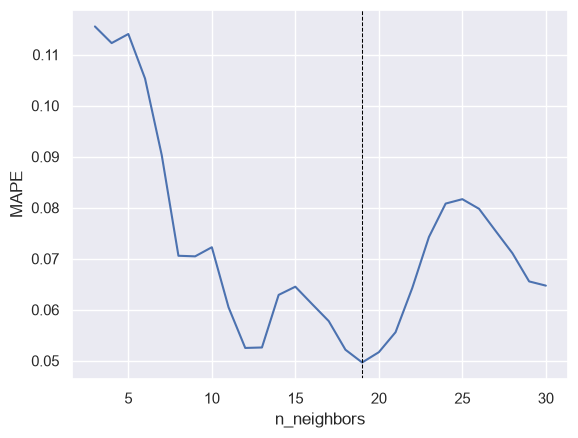

Найкраще значення n_neighbors: 19


In [15]:
scores = {}

for k in range(3, 31):
    mod = KNeighborsRegressor(n_neighbors=k).fit(X_train_prep, y_train)
    scores[k] = mean_absolute_percentage_error(
        y_valid, mod.predict(X_valid_prep))

scores = pd.Series(scores)

ax = sns.lineplot(scores)
ax.set(xlabel='n_neighbors', ylabel='MAPE')

ax.axvline(x=scores.idxmin(), c='black', linestyle='--', linewidth=0.75)

plt.show()

print(f'Найкраще значення n_neighbors: {scores.idxmin()}')

При малих значеннях `k` модель фактично «копіює» окремі спостереження з тренувального набору й помиляється сильніше, а надто великі значення надмірно згладжують прогноз. Оптимум досягається приблизно на 19 сусідах.

In [16]:
model = KNeighborsRegressor(n_neighbors=19).fit(X_train_prep, y_train)

### 7. Прогноз для валідаційного набору й оцінка точності

In [17]:
y_pred = model.predict(X_valid_prep)

pd.DataFrame({'Salary_fact': y_valid,
              'Salary_pred': y_pred.round(0)})

,Salary_fact,Salary_pred
0,109300,103132.0
1,84800,89921.0
2,98900,91237.0
3,116500,119184.0
4,75800,76868.0
5,97300,98974.0
6,69800,76711.0


In [18]:
mape = mean_absolute_percentage_error(y_valid, y_pred)
mae = mean_absolute_error(y_valid, y_pred)
r_sq = r2_score(y_valid, y_pred)

print(f'Validation MAPE: {mape:.2%}')
print(f'Validation MAE: {mae:.0f}')
print(f'Validation R2: {r_sq:.2f}')

Validation MAPE: 4.97%
Validation MAE: 4470
Validation R2: 0.90


### 8. Висновки

1. Отримано помилку MAPE на валідаційному наборі ~4.97%, тобто прогноз зарплати в середньому відхиляється від фактичного значення приблизно на 5%. Середня абсолютна похибка (MAE) складає близько 4.5 тис., а коефіцієнт детермінації R2 = 0.90, що свідчить про добру якість моделі.
2. Дослідницький аналіз показав, що з дев'яти доступних колонок для моделювання придатні лише п'ять. `Name` і `Phone_Number` є ідентифікаторами й не містять корисної інформації, а `Date_Of_Birth` має некоректні значення й практично не корелює із зарплатою.
3. Найінформативнішою ознакою виявився стаж роботи (кореляція із зарплатою 0.81). Решта ознак — рівень освіти, категорія університету, посада та наявність сертифіката — також помітно впливають на рівень оплати.
4. Для kNN критично важливою є нормалізація ознак, оскільки алгоритм працює з відстанями між об'єктами. Без приведення до єдиного масштабу ознака `Experience` домінувала б над закодованими категоріальними ознаками.
5. Підбір гіперпараметра `n_neighbors` суттєво вплинув на результат: при k=5 помилка складала понад 11%, а при k=19 зменшилась приблизно вдвічі. Це пояснюється тим, що валідаційний набір містить комбінації ознак, яких немає в тренувальному (зокрема стаж 6 і 7 років), тому усереднення по більшій кількості сусідів дає стабільніший прогноз.
6. Основне обмеження моделі — невеликий обсяг даних (249 спостережень для навчання і лише 7 для валідації), тому отриману метрику варто сприймати як орієнтовну. Для надійнішої оцінки доцільно було б застосувати крос-валідацію на більшому наборі даних.